# 📘 9.3 Implicit Methods for Solving Ordinary Differential Equations
###

This notebook introduces **Implicit** solvers as a method for overcoming the challenges imposed by the Stiff ODEs covered in Notebook [9.2](https://colab.research.google.com/drive/1OJGXVRTicMWzEgBrn19HvCh59nK6Wyq-?usp=sharing).


---

### 🎯 Learning Objectives
> By the end of this notebook, you should be able to:
>
> * Recognise the difference between an **implicit** and **explicit** method;
> * Formulate a backward implicit Euler method;
> * Appreciate the greater stability offered by the **implicit** formulation;
> * Calculate the stability of a basic **implicit** method;
> * Understand why **implicit** methods are unconditionally stable when applied to linear ODEs;
> * Appreciate that even though stability might allow a larger time step, a small time step may still be needed to limit truncation errors;
> * Explain why a non-linear ODE may require an iterative Newton solution at each time-step;
> * Apply linearisation to formulate a **semi-implicit** Euler method.

## 📂 9.3.0 How to use this notebook

This notebook introduces the concepts behind **implicit** solvers, how these methods impact stability and how they may be applied to linear and non-linear ODEs.

> ### 🧭 Theory preface
> You do not need to be able to derive Newton's Root finding method, but you should be able to apply this to extend the methods previously used in Notebooks 9.1 and 9.2, to formulate the update associated with a backward Euler method.
>
> Think of these methods and recipes for solving ODEs and appreciate why you might want to use an **implicit** method in favour of an **explicit** one.

## 📂 9.3.1 Implicit vs Explicit Methods

---

So far, we have explored *purely* **explicit** discretisation and methods of solving ordinary differential equations.

> ### 📖 Definition
> **Explicit Methods:** calculate the state of a system at a later time, e.g. $y_{n+1}$, from the state of the system (y_n, t_n, etc.) at the current time.
> $$ y(t+\Delta t) = f(y(t))$$

For example, the Euler methods we have used to solve $\mbox{d}y/\mbox{d}t = -\lambda y$,
$$ y_{n+1} = y_n + y'_nh,$$

is an **explicit method**, as all the terms used to evolve $y$ to the next time-step are based on the current time step.

Explicit methods are the most logical approach, for an ODE as $y'_n$ is directly computable from the right-hand side of the ODE for any given $y_n$.

> ### 📖 Definition
> **Implicit Methods:** calculate the state of a system at a later time, e.g. $y_{n+1}$, from the state of the system at both the current and updated - later - time,
> $$ y(t+\Delta t) = f\left(y(t),y(t+\Delta t)\right)$$

The term **explicit** comes from the fact that the value of $y(t+\delta t)$ is given *explicitly* by the values at time $t$. For an **implicit** method this is not the case.

This begs the question ...

---
*How do we solve for $y(t+\Delta t)$ if it is a function of y$(t+\Delta t)$?*

---

## 📂 9.3.2 Forward (Explicit) Euler and the Backward (Implicit) Euler

---

In order to explain how we can practically solve an implicit method, let's consider the **explicit** Euler method we have been looking at over the past several notebooks.

For the basic ODE,
$$\frac{\mbox{d}y}{\mbox{d}t} = -\lambda y,$$

the Explicit (or forward) Euler method is
$$ y_{n+1} = y_n + hy'_n,$$
where the update to $y$ is purely a function of the current value of $y$. Substitute in our ODE for the gradient at $n$ and we get the update,
$$ y_{n+1} = (1-\lambda h)y_n.$$

In this method we are essentially assuming that the gradient $y'$ between the points $n$ and $n+1$ is constant and given by the gradient at $n$.

Consider what would happen if instead of using the gradient at the current
$n$, you instead used the gradient at the updated $n+1$, i.e.

$$y_{n+1} = y_n + hy'_{n+1}.$$

This is now an **implicit** expression for $y_{n+1}$ and is often referred to as *backward Euler*.

As for the *forward Euler* we can substitute in the ODE in place of the gradient in this *backward Euler*, which yields

\begin{align}
 y_{n+1} &= y_n - h\lambda y_{n+1},\\
 y_{n+1}(1+ h\lambda) &= y_n,\\
 y_{n+1} &=\frac{y_n}{1+\lambda h}\tag{9.16}
\end{align}

> ### ⚠️ Point of note
> In this case we get an expression that we can still evaluate for $y_{n+1}$ as a function of $y_n$, however the *formulation* that we used to get there is still **implicit**, it's just the nature of the ODE that allows for a relatively simple solution.

## 📂 9.3.3 Stability of the Backward (Implicit) Euler

---

So we can formulate an *implicit* form of the Euler equation. So what?

To understand the benefit of this approach, we need to look at the stability of this method.

Let's follow our now well-worn stability approach of introducing a perturbation $\delta_{y_n}$ to $y_n$ into the update equation for the backward Euler, Equation 9.16, and seeing how it propagates.

\begin{align}
\tilde{y}_{n+1} &= \frac{\tilde{y}_n}{1+\lambda h}\\
y_{n+1}+\delta_{y_{n+1}} &= \frac{y_n+\delta_{y_n}}{1+\lambda h}
\end{align}

Subtracting Equation 9.16 leaves,
$$ \delta_{y_{n+1}} = \frac{\delta_{y_n}}{1+\lambda h},$$

which corresponds to an amplification factor
$$A = \left|\frac{1}{1+\lambda h}\right|.$$

From this we can see that the *backward (implicit) Euler method* is **unconditionally stable**.

Compare this with the explicit method for the same ODE. which is only stable for $0 < \lambda h < 2$.

> ### ⚠️ Point of note
> *Implicit methods* are **unconditionally stable** for linear ODEs and are also generally more stable than *explicit methods* for non-linear ODEs

## 🧪 The Implicit Euler Solution of a Stiff ODE

Let's return to the stiff ODE introduced at the start of Notebook [9.2](https://colab.research.google.com/drive/1OJGXVRTicMWzEgBrn19HvCh59nK6Wyq-?usp=sharing), i.e,
$$\frac{\mbox{d}y}{\mbox{d}t}=-1000y+3000-2000e^{-t},$$

 and compare this **Implicit** Euler method with our previous **Explicit** Euler Method.

 The **implicit Euler** update is

\begin{align}
y_{n+1} &= y_n + h\left(-1000 y_{n+1}\right) +h\left(3000-2000e^{-t_{n+1}}\right)\\
y_{n+1}(1+1000 h) &= y_n + h\left(3000-2000e^{-t_{n+1}}\right)\\
y_{n+1} &= \frac{y_n + h\left(3000-2000e^{-t_{n+1}}\right)}{1+1000 h}\\
\end{align}

Hence, the **explicit** and **implicit** methods can be evaluated using the following functions.

In [ ]:
# --- Explicit Euler Function ---
def explicit_euler(f, y0, t0, t_end, h):
    num_steps = int((t_end - t0) / h)
    t_values = np.linspace(t0, t_end, num_steps + 1)
    y_values = np.zeros(num_steps + 1)
    y_values[0] = y0
    for i in range(num_steps):
        y_values[i+1] = y_values[i] + h * f(t_values[i], y_values[i])
    return t_values, y_values

# --- Implicit Euler Function ---
def implicit_euler(y0, t0, t_end, h):
    num_steps = int((t_end - t0) / h)
    t_values = np.linspace(t0, t_end, num_steps + 1)
    y_values = np.zeros(num_steps + 1)
    y_values[0] = y0
    for i in range(num_steps):
        y_values[i+1] = (y_values[i] + h * (3000 - 2000 * np.exp(-t_values[i+1]))) / (1 + 1000 * h)
    return t_values, y_values

The impact of the step size used in both methods is demonstrated in the figures below for the rapid transient and the slower mode.

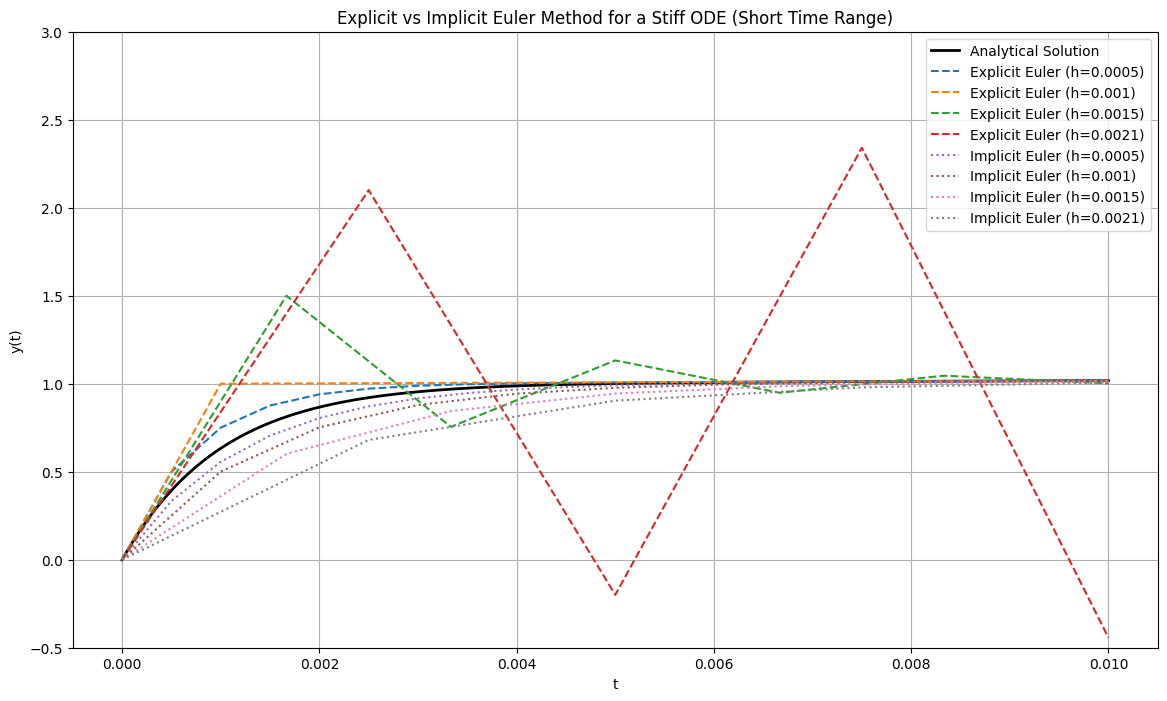

In [ ]:
# @title Implicit and Explicit Euler Method for a Stiff ODE
import numpy as np
import matplotlib.pyplot as plt

# Define the ODE function dy/dt = f(t, y)
def f(t, y):
    return -1000 * y + 3000 - 2000 * np.exp(-t)

# Define the analytical solution for comparison
def y_analytical(t):
    return 3 - 0.998 * np.exp(-1000 * t) - 2.002 * np.exp(-t)

# Initial conditions
y0 = 0.0
t0 = 0.0

# --- Simulation for a short time range (0 to 0.01) ---
t_end_short = 0.01

# Step sizes to compare
step_sizes = [0.0005, 0.001, 0.0015, 0.0021]

plt.figure(figsize=(14, 8))

# Analytical Solution
t_analytical_short = np.linspace(t0, t_end_short, 500)
plt.plot(t_analytical_short, y_analytical(t_analytical_short), 'k-', linewidth=2, label='Analytical Solution')

# Plot Explicit Euler results
for h in step_sizes:
    t_exp, y_exp = explicit_euler(f, y0, t0, t_end_short, h)
    plt.plot(t_exp, y_exp, '--', label=f'Explicit Euler (h={h})')

# Plot Implicit Euler results
for h in step_sizes:
    t_imp, y_imp = implicit_euler(y0, t0, t_end_short, h)
    plt.plot(t_imp, y_imp, ':', label=f'Implicit Euler (h={h})')

plt.xlabel('t')
plt.ylabel('y(t)')
plt.title('Explicit vs Implicit Euler Method for a Stiff ODE (Short Time Range)')
plt.legend()
plt.grid(True)
plt.ylim(-0.5, 3)
plt.show()

We can see that the implicit method is indeed more stable than the explicit methods for the same time step.

---
Given the implicit methods is unconditionally stable, can we just choose a really large time step?

---
The answer to this question can be seen from the above plot. As this is a linear ODE it is unconditionally stable, but this is still an Euler method with a truncation error $\mathcal{O}(h^2)$.

While we can use a large time step, remain stable, thereby reducing the number of steps and the computational cost, a large time step will still increase truncation error and reduce the accuracy of our solution.

> ### ⚠️ Point of note
> Remember, the selection of a time step depends not only on stability, but also truncation error.
> * select a time step within the stability margins of your method;
> * select a time step that balances computational cost with required accuracy.

For the toy calculations we have looked at so far the computational time might not seem that important, but if you have to solve a system of ODES,
$$ \mathbf{y}' = -\mathbf{C}\cdot\mathbf{y},$$

where $\mathbf{C}$ is a large matrix, the cost becomes significant.

## 📂 9.3.4 Implicit Solutions of Non-Linear ODEs

---

In sections 9.3.2 and 9.3.3, we were able to come up with an equation for $y_{n+1}$ that removed $y_{n+1}$ from the left-hand side, leaving a function that was only in terms of $y_n$. This happened as the result of the *linear* nature of the ODE.

What do we do when our ODE is non-linear (or we have a system of ODEs)?

Consider the solution of the ODE
$$\frac{\mbox{d}y}{\mbox{d}t} = \cos y.$$

A forward **explicit** Euler update is
$$ y_{n+1} = y_n + h\cos{y_n},$$

which can be solved for an update to the next $y$ based on the current value of $y$.

The backward **implicit** Euler is
$$ y_{n+1} = y_n + h\cos y_{n+1}.\tag{9.17}$$

Unlike the previous examples, we can CANNOT move the $y_{n+1}$ terms from the right-hand side to the left and collect like terms.

Instead, what we have to do is try to find the value of $y_{n+1}$ that minimises the difference between the left- and right-hand sides of Equation 9.17.

This is easier to do if we rearrange this equation as
$$f(y_{n+1}) = y_{n+1} - y_n - h\cos y_{n+1} = 0,$$

such that $y_{n+1}$ is now the root of the equation, meaning we can use a root finding method like Newton-Raphson (aka Newton's Method).

### 🔹 Newton's Method

Newton's Method is a root finding method that uses the local gradient and an initial guess at the root, to estimate the change in $y$ that is needed to bring the equation to zero. This is probably best described graphically, as depicted in Figure 9.3, where the function in blue is approximated by its local gradient, resulting in the red tangent. This linear approximation is used to estimate where the function goes to zero, and enables the next guess at the root.

<figure>
  <img src="https://drive.google.com/uc?id=1aycoAms35Bijaz7hwGGoLIGdd6uIVEgD" alt="" style="width:100%;max-width:400px;background-color: white">
  <figcaption style="text-align: center; font-style: italic; margin-top: 5px;">
    Figure 9.3: Newton's Method - approximating the function by its local tangent to estimate the functions root -(From https://en.wikipedia.org/wiki/Newton%27s_method).
  </figcaption>
</figure>

Mathematically - thinking $y=mx+c$ for a straight line or in this case  
$$f(y_{n+1}) \approx f'(y^k_{n+1})y_{n+1} + c,$$

where $y^k_{n+1}$ is a guess at the value of the root, and $c$ is the point where the tangent to the function at $y^k_{n+1}$ intersects the vertical axis, e.g. $c = f(y^k_{n+1}) - f'(y^k_{n+1})y^k_{n+1}$. Substiting in this intersection, $c$, the function is approximated as

$$f(y_{n+1}) \approx f(y^k_{n+1}) +f'(y^k_{n+1})\left(y_{n+1} - y^k_{n+1}\right).\tag{9.18}$$

Given we want $y_{n+1}$ that yields $f(y_{n+1})=0$,

\begin{align}
0 &\approx f(y^k_{n+1}) +f'(y^k_{n+1})\left(y_{n+1} - y^k_{n+1}\right)\\
y_{n+1} - y^k_{n+1} &\approx \frac{-f(y^k_{n+1})}{f'(y^k_{n+1})}\\
y_{n+1} &\approx y^k_{n+1} - \frac{f(y^k_{n+1})}{f'(y^k_{n+1})}
\end{align}

The $k$ introduced above represents a guess at the root, and this can be iterated to improve our estimate of the root as

$$y^{k+1}_{n+1} \approx y^k_{n+1} - \frac{f(y^k_{n+1})}{f'(y^k_{n+1})},$$

i.e. for each guess at the root, we estimate the root and update our guess, which iteratively refines the guess towards the true root as the tangent approximation improves.

In practice, this would require an iterative calculation of $y_{n+1}$ for each time-step $n$, which significantly increases the computational cost.









### 🔹 Semi-Implicit Method - Newton-Style Linearisation

In the Newton Method, we introduced a linear approximation to the function $f(y_{n+1})$ by using the local tangent, which led us to Equation 9.18.

We can do a similar linearisation if we take our guess at the root, as the value of $y$ at the current time step, i.e. let $y^k_{n+1} = y_n$. In doing so, Equation 9.18 becomes

$$f(y_{n+1}) \approx f(y^n) +f'(y^n)\left(y_{n+1} - y_n\right)\tag{9.19}.$$

While, $y_{n+1}$ still appears on the right-hand side, it is no longer a part of the gradient term. We will see why this is important in a moment.

Returning to the backward **implicit** Euler from Equation 9.17, and let $g$ be a function of $y_{n+1}$ such that
$$ y_{n+1} = y_n + hg(y_{n+1}),$$

where

$$g(y_{n+1}) = \cos(y_{n+1})$$

Applying the linearisation from Equation 9.19 to $g(y_{n+1})$, we can express our backward Euler as

$$y_{n+1} = y_n + h\left[g(y_n) + \frac{\mbox{d}g}{\mbox{d}y}(y_n)\left(y_{n+1}-y_n\right)\right]$$

We can now collect like terms of $y_{n+1}$ as we did for the linear ODE in section 9.3.2, i.e.

\begin{align}
y_{n+1}\left(1-h\frac{\mbox{d}g}{\mbox{d}y}(y_n)\right) &= y_n\left(1-h\frac{\mbox{d}g}{\mbox{d}y}(y_n)\right)+hg(y_n)\\
y_{n+1} &= y_n+h\frac{g(y_n)}{1-h\frac{\mbox{d}g}{\mbox{d}y}(y_n)}
\end{align}

This is written more cleanly as

$$ y_{n+1} = y_n +h\left[1-h\frac{\mbox{d}g}{\mbox{d}y}(y_n)\right]^{-1}g(y_n).\tag{9.20}$$

The right-hand side is now only a function of $y_n$ so it can be solved without the need to iterate to find the value of $y^{k+1}_{n+1}$.

Owing to the linearisation that we performed following Equation 9.19, this method is no longer *strictly implicit*.

> ### ⚠️ Point of note
> Solving **implicit** methods by linearisation is called a **semi-implicit** method - in this case the **semi-implicit Euler method**.
>
> These methods are not guaranteed to be stable - but they usually are.

While in these examples we have only dealt with **implicit** *first-order* methods, these principles can also be applied to formulate implicit mid-point and Runge-Kutta style methods.

## 🔗 Bridge to Notebook 9.4

This notebook demonstrated the power of **implicit methods** in addressing the stability issues posed by stiff Ordinary Differential Equations. We established that methods like the Backward Euler can offer **unconditional stability** for linear ODEs, a significant improvement over their explicit counterparts. Furthermore, we explored how **Newton's method** can be used to iteratively solve for the update at each time step - with added computational cost - and how **semi-implicit methods**, utilising a linearisation technique, can remove the iterations, though sometimes at the expense of some of the unconditional stability of fully implicit methods.

While implicit methods enhance stability and allow for larger time steps, the balance between computational cost and truncation error remains a critical consideration.

Notebook 9.4 will extend these methods, so far applied only to initial values problems, to the solution of **boundary value** problems.

#🤖 AI Acknowledgment

MS CoPilot v25.6.440430001 was used to proof read this notebook and provided the basis for the **implicit** and **explicit** Euler code and plots.